# ¿Cuánto le cuestan las demoras de entrega a un e-commerce?
**Análisis exploratorio — Olist (Brasil), ene-2017 a ago-2018 · ~97.900 pedidos reales**

**Pregunta de negocio:** la empresa crece en ventas, pero ¿la logística acompaña? Quiero medir
qué tan seguido se entrega tarde, dónde y por qué, y cuánto impacta en la satisfacción y la recompra.

Datos: *Brazilian E-Commerce Public Dataset by Olist* (Kaggle). Las tablas limpias salen de `src/clean.py`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pathlib import Path

FIG = Path('../reports/figures'); FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#b7b6b0'
INK, INK2 = '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.figsize': (10, 4.2), 'figure.dpi': 110, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.spines.left': False, 'axes.edgecolor': GRAY,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False,
})
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f'{name}.png', bbox_inches='tight', facecolor='white'); plt.show()

orders = pd.read_csv('../data/processed/orders.csv', parse_dates=['order_purchase_timestamp'])
items = pd.read_csv('../data/processed/order_items.csv')
valid = orders[~orders.order_status.isin(['canceled', 'unavailable'])]
deliv = orders[orders.is_delivered].copy()
deliv['is_late'] = deliv.is_late.astype(bool)
print(f'Pedidos válidos: {len(valid):,} | entregados: {len(deliv):,} | clientes: {valid.customer_unique_id.nunique():,}')

Pedidos válidos: 97,910 | entregados: 96,203 | clientes: 94,707


## 1. Panorama comercial

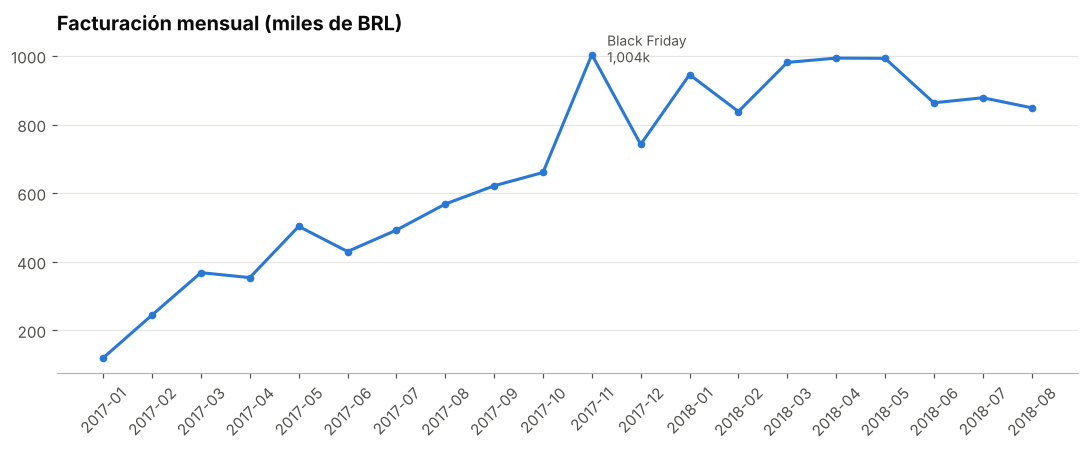

Crecimiento ago-2018 vs ago-2017: 49%


In [2]:
m = valid.groupby('order_month').product_value.sum() / 1e3
fig, ax = plt.subplots()
ax.plot(m.index, m.values, color=BLUE, lw=2, marker='o', ms=4)
ax.set_title('Facturación mensual (miles de BRL)')
ax.tick_params(axis='x', rotation=45)
pk = m.idxmax(); ax.annotate(f'Black Friday\n{m.max():,.0f}k', (pk, m.max()), xytext=(10, -5),
                             textcoords='offset points', color=INK2, fontsize=9)
save('01_facturacion_mensual')
print(f"Crecimiento ago-2018 vs ago-2017: {m['2018-08']/m['2017-08']-1:.0%}")

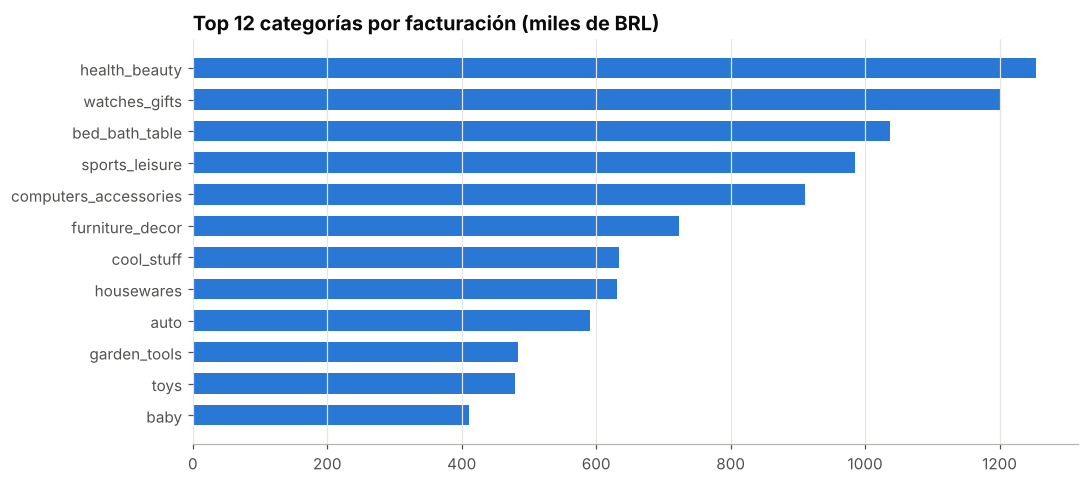

Categorías totales: 74 | las 10 primeras concentran el 62% de la facturación


In [3]:
cat = items.groupby('category').price.sum().sort_values(ascending=False)
share = cat.cumsum() / cat.sum()
top = cat.head(12) / 1e3
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(top.index[::-1], top.values[::-1], color=BLUE, height=0.65)
ax.set_title('Top 12 categorías por facturación (miles de BRL)'); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
save('02_top_categorias')
print(f'Categorías totales: {len(cat)} | las 10 primeras concentran el {share.iloc[9]:.0%} de la facturación')

**Lectura:** la facturación creció ~50% interanual (ago-2018 vs ago-2017), con el pico de noviembre 2017 (Black Friday).
La facturación está concentrada: 10 de 74 categorías explican el 62% del total.

## 2. Logística: ¿cuánto y dónde se entrega tarde?

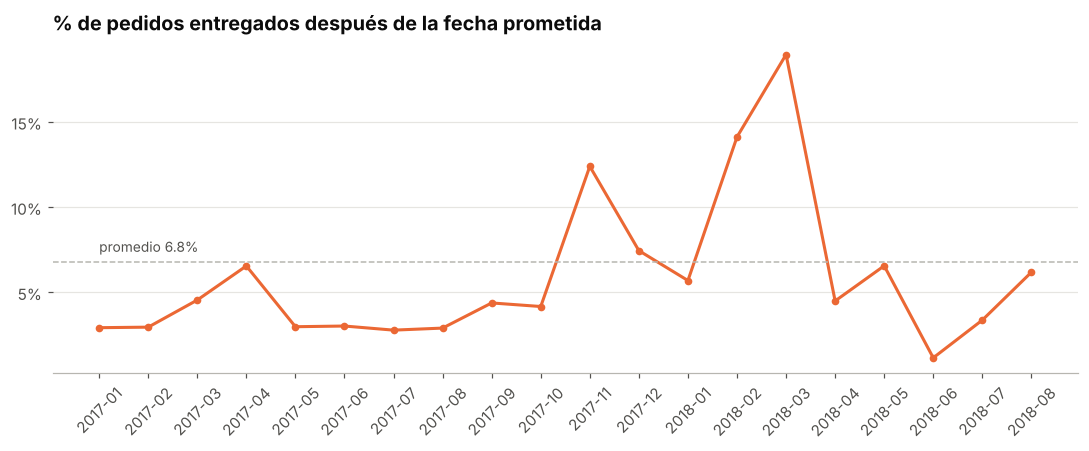

order_month
2018-03    19.0%
2018-02    14.1%
2017-11    12.4%
Name: is_late, dtype: str


In [4]:
late_m = deliv.groupby('order_month').is_late.mean()
fig, ax = plt.subplots()
ax.plot(late_m.index, late_m.values, color=ORANGE, lw=2, marker='o', ms=4)
ax.axhline(deliv.is_late.mean(), color=GRAY, ls='--', lw=1)
ax.text(0, deliv.is_late.mean() + 0.006, f'promedio {deliv.is_late.mean():.1%}', color=INK2, fontsize=9)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.05)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_title('% de pedidos entregados después de la fecha prometida')
ax.tick_params(axis='x', rotation=45)
save('03_atraso_mensual')
print(late_m.sort_values(ascending=False).head(3).map('{:.1%}'.format))

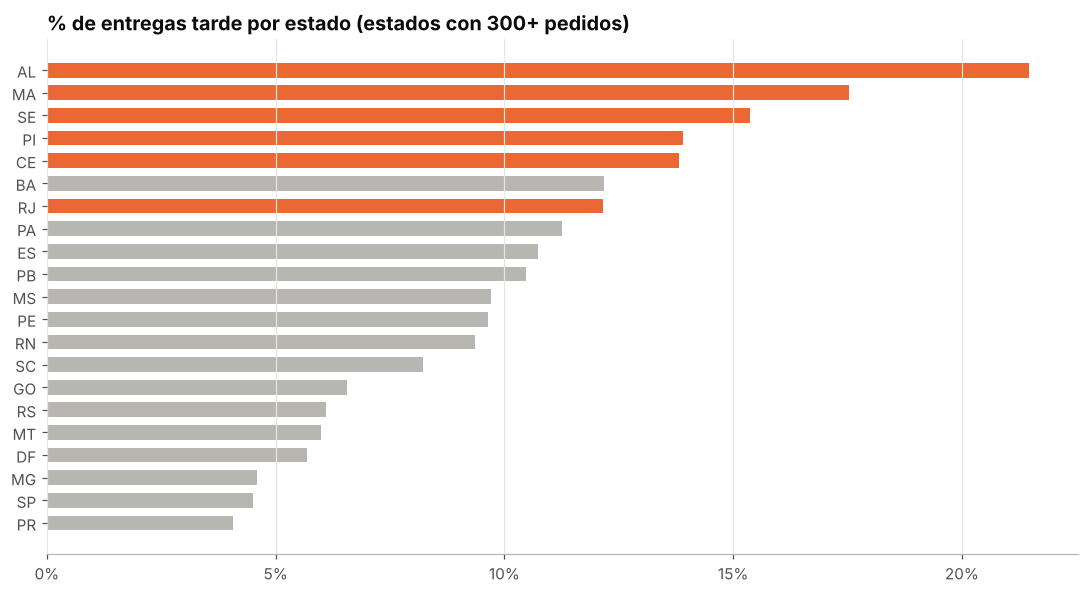

RJ: 12,310 pedidos, 12.1% tarde (2,7x São Paulo: 4.5%)


In [5]:
st = deliv.groupby('customer_state').agg(pedidos=('order_id', 'count'), pct_tarde=('is_late', 'mean'))
st = st[st.pedidos >= 300].sort_values('pct_tarde')
colors = [ORANGE if s in ('RJ',) or p > 0.13 else GRAY for s, p in zip(st.index, st.pct_tarde)]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(st.index, st.pct_tarde, color=colors, height=0.65)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('% de entregas tarde por estado (estados con 300+ pedidos)')
save('04_atraso_por_estado')
rj = st.loc['RJ']; print(f"RJ: {rj.pedidos:,.0f} pedidos, {rj.pct_tarde:.1%} tarde (2,7x São Paulo: {st.loc['SP','pct_tarde']:.1%})")

**Lectura:** el 6,8% de los pedidos llega tarde, pero el promedio esconde dos crisis: nov-2017 (12%) y
feb-mar 2018 (14-19%). El problema es geográfico: el Nordeste supera el 13%, y **Río de Janeiro**, el
segundo mercado en volumen, entrega tarde el 12% de las veces, casi el triple que São Paulo.

## 3. ¿Cuánto le importa al cliente?

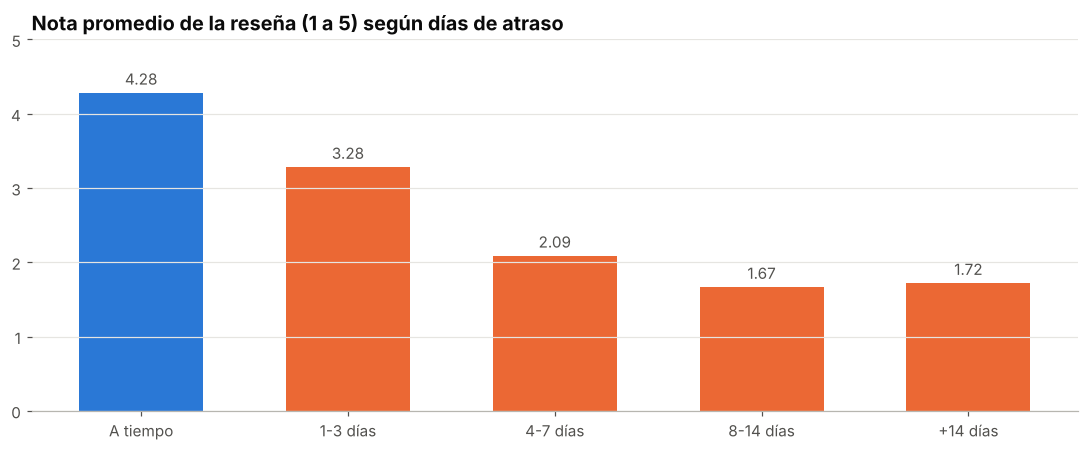

Reseñas negativas (1-2): a tiempo 9.5% vs tarde 62.9% -> 6.6x


In [6]:
bins = [-999, 0, 3, 7, 14, 999]
labels = ['A tiempo', '1-3 días', '4-7 días', '8-14 días', '+14 días']
r = deliv.dropna(subset=['review_score']).copy()
r['tramo'] = pd.cut(r.days_late, bins, labels=labels)
nota = r.groupby('tramo', observed=True).review_score.mean()
fig, ax = plt.subplots()
bars = ax.bar(nota.index, nota.values, color=[BLUE] + [ORANGE] * 4, width=0.6)
ax.bar_label(bars, fmt='%.2f', color=INK2, padding=3)
ax.set_ylim(0, 5); ax.set_title('Nota promedio de la reseña (1 a 5) según días de atraso')
save('05_nota_por_atraso')
neg = r.groupby('is_late').review_score.apply(lambda s: (s <= 2).mean())
print(f"Reseñas negativas (1-2): a tiempo {neg[False]:.1%} vs tarde {neg[True]:.1%} -> {neg[True]/neg[False]:.1f}x")

**Lectura:** el atraso es el factor que más destruye la satisfacción. Con solo 1-3 días tarde la nota cae
de 4,3 a 3,3, y con más de una semana queda debajo de 2. **El 63% de los pedidos tardíos recibe una reseña
negativa, contra el 9,5% de los que llegan a tiempo (6,6 veces más).**

## 4. ¿Por qué se entrega tarde?

Pedidos que el vendedor despachó tarde al correo: 8.9%
  -> llegan tarde al cliente: 21.1% vs 5.4% cuando despacha a tiempo (3.9x)


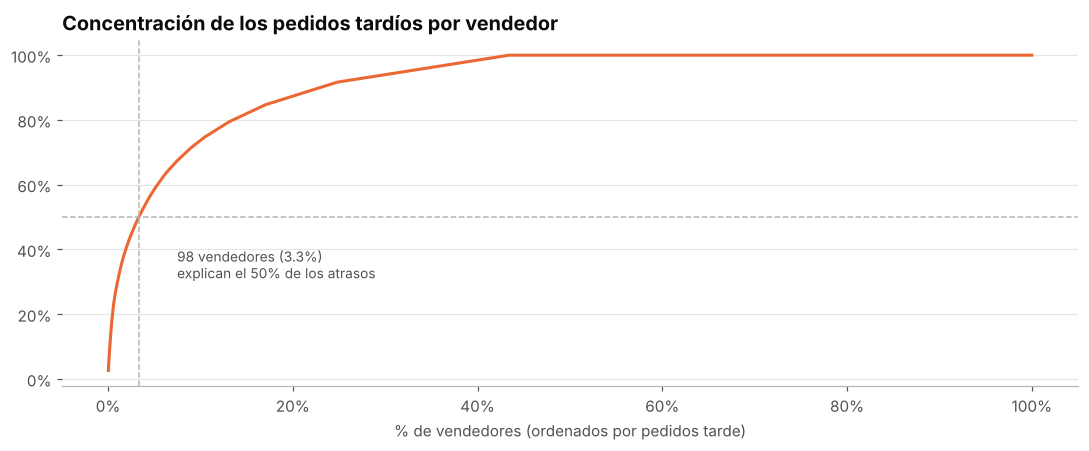

In [7]:
h = deliv.dropna(subset=['seller_late_handoff']).copy()
h['seller_late_handoff'] = h.seller_late_handoff.astype(bool)
t = h.groupby('seller_late_handoff').is_late.agg(['mean', 'count'])
print(f"Pedidos que el vendedor despachó tarde al correo: {t.loc[True,'count']/t['count'].sum():.1%}")
print(f"  -> llegan tarde al cliente: {t.loc[True,'mean']:.1%} vs {t.loc[False,'mean']:.1%} cuando despacha a tiempo ({t.loc[True,'mean']/t.loc[False,'mean']:.1f}x)")

sv = items.drop_duplicates('order_id')[['order_id', 'seller_id']].merge(deliv[['order_id', 'is_late']], on='order_id')
g = sv.groupby('seller_id').is_late.sum().sort_values(ascending=False)
cum = g.cumsum() / g.sum()
n50 = (cum < 0.5).sum() + 1
fig, ax = plt.subplots()
x = np.arange(1, len(cum) + 1) / len(cum)
ax.plot(x, cum.values, color=ORANGE, lw=2)
ax.axhline(0.5, color=GRAY, ls='--', lw=1); ax.axvline(n50 / len(cum), color=GRAY, ls='--', lw=1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, 0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_xlabel('% de vendedores (ordenados por pedidos tarde)'); ax.set_title('Concentración de los pedidos tardíos por vendedor')
ax.annotate(f'{n50} vendedores ({n50/len(cum):.1%})\nexplican el 50% de los atrasos', (n50/len(cum), 0.5),
            xytext=(25, -40), textcoords='offset points', color=INK2, fontsize=9)
save('06_concentracion_vendedores')

**Lectura:** una parte del problema no es del correo sino del vendedor. Cuando despacha después del
límite pactado (9% de los pedidos), el pedido llega tarde 4 veces más seguido. Y el problema está
concentrado: **menos de 100 vendedores (3%) generan la mitad de todos los atrasos.**

## 5. Recompra

In [8]:
first = deliv[deliv.customer_order_seq == 1]
rep = first.groupby('is_late').customer_repurchased.mean()
print(f"Tasa de recompra general: {valid.groupby('customer_unique_id').size().gt(1).mean():.1%}")
print(f"Recompra si el primer pedido llegó a tiempo: {rep[False]:.2%} | si llegó tarde: {rep[True]:.2%} ({rep[True]/rep[False]-1:.0%})")

Tasa de recompra general: 3.0%
Recompra si el primer pedido llegó a tiempo: 3.12% | si llegó tarde: 2.55% (-18%)


**Lectura:** la recompra es muy baja en general (~3%), lo que hace que cada cliente nuevo cueste caro.
Cuando la primera compra llega tarde, la probabilidad de volver cae un 18% adicional.

## 6. Impacto estimado de una acción concreta

In [9]:
# Escenario: los vendedores que despachan tarde pasan a despachar a tiempo
# (sus pedidos tendrían la tasa de atraso de los que sí cumplen).
late_now = t.loc[True, 'count'] * t.loc[True, 'mean']
late_fixed = t.loc[True, 'count'] * t.loc[False, 'mean']
avoided = late_now - late_fixed
neg_avoided = avoided * (neg[True] - neg[False])
print(f'Pedidos tardíos evitables: {avoided:,.0f} ({avoided/deliv.is_late.sum():.0%} de todos los atrasos)')
print(f'Reseñas negativas evitables: {neg_avoided:,.0f}')

Pedidos tardíos evitables: 1,349 (21% de todos los atrasos)
Reseñas negativas evitables: 720


## Conclusiones y recomendaciones

| # | Hallazgo | Recomendación |
|---|----------|---------------|
| 1 | Un pedido tarde tiene **6,6x más probabilidad** de reseña negativa (63% vs 9,5%) | Tratar la puntualidad como KPI comercial, no solo logístico |
| 2 | **98 vendedores (3%) explican el 50% de los atrasos**; el despacho tardío multiplica x4 el riesgo | Programa de seguimiento a esos vendedores: alertas, penalidades o menor visibilidad |
| 3 | Atraso de 12-19% en picos (Black Friday, feb-mar 2018) | Plan de capacidad logística antes de fechas de alta demanda |
| 4 | Nordeste y Río de Janeiro superan el 12% de atraso | Revisar transportista y fecha prometida en esas rutas |

**Impacto:** solo con que los vendedores despachen a tiempo se evitarían ~1.350 pedidos tardíos (≈21% del total)
y ~720 reseñas negativas en el período analizado.

**Limitaciones:** no hay datos de costo logístico ni del transportista usado; la relación entre atraso y recompra es
una asociación, no una causalidad probada.